<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-09/breast-cancer-tree.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Classifying cell-nucleus measurements

Thirty measured properties describe a sampled breast mass. The target is malignant or benign. This teaching comparison illustrates prediction and evaluation on this dataset. It does not establish clinical performance.

We use the same observations and score for every model. Run the cells in order. The complete application uses the standard scikit-learn interface.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import balanced_accuracy_score, root_mean_squared_error, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
SEED = 1975
Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

## Data

Each row is an observation. The columns of `X` are the inputs, and `y` is the target. Display a few rows before fitting.

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target
feature_names = list(data.feature_names)
classification = True
print("Input shape", X.shape)
display(pd.DataFrame(X[:5], columns=feature_names).assign(target=y[:5]))

Input shape (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## Separate fitting, validation and test observations

Fitting observations teach the models. Validation observations let us inspect the declared settings. Test observations assess the frozen comparison. All three settings below are fixed teaching choices, so this short example does not tune a large parameter grid.

In [3]:
pool, test = train_test_split(np.arange(len(y)), test_size=.2, random_state=SEED,
                             stratify=y if classification else None)
fit, val = train_test_split(pool, test_size=.25, random_state=SEED,
                           stratify=y[pool] if classification else None)
print("Fitting / validation / test", len(fit), len(val), len(test))

Fitting / validation / test 341 114 114


## Fit three estimators

The tree asks a short sequence of questions. The forest combines many randomized trees. The neural network combines inputs through a hidden layer. `fit` learns each model and `predict` supplies its answers. The network pipeline scales its inputs with fitting statistics. For regression, target scaling is also fitted on fitting observations and predictions are returned in the original units.

In [4]:
models = {
    "Tree": DecisionTreeClassifier(max_depth=2, min_samples_leaf=5, random_state=SEED),
    "Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=2, random_state=SEED, n_jobs=2),
    "Network": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16,),
                  activation="tanh", solver="lbfgs", alpha=1., max_iter=5000, random_state=SEED))}
for model in models.values():
    model.fit(X[fit], y[fit])

## Inspect a tree and one prediction

Read the displayed questions, then predict the target of the validation observation before checking the output. Leaf values summarize the fitting targets reaching that leaf. Class probabilities and hard decisions carry different information.

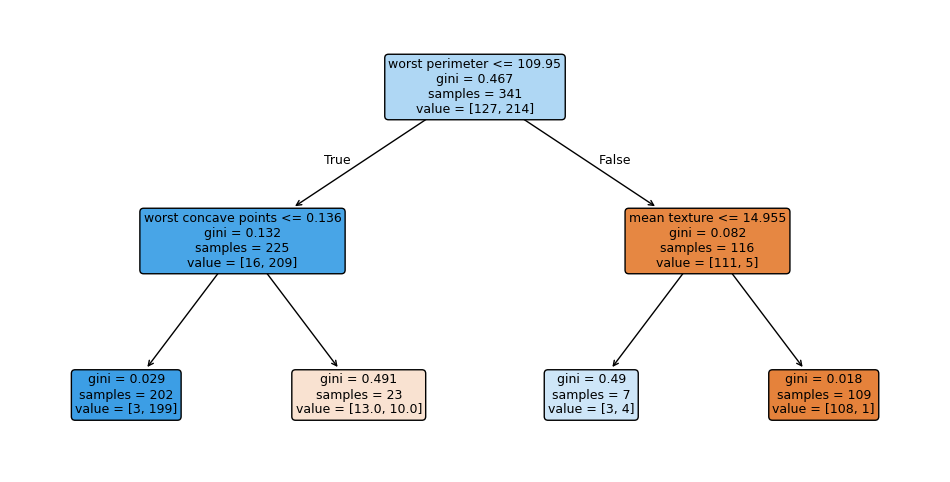

Measured features [1.308e+01 1.571e+01 8.563e+01 5.200e+02 1.075e-01 1.270e-01 4.568e-02
 3.110e-02 1.967e-01 6.811e-02 1.852e-01 7.477e-01 1.383e+00 1.467e+01
 4.097e-03 1.898e-02 1.698e-02 6.490e-03 1.678e-02 2.425e-03 1.450e+01
 2.049e+01 9.609e+01 6.305e+02 1.312e-01 2.776e-01 1.890e-01 7.283e-02
 3.184e-01 8.183e-02]
Tree prediction [1]
Class probabilities [0.01485149 0.98514851]
Forest prediction [1]
Class probabilities [0.00333333 0.99666667]
Network prediction [1]
Class probabilities [0.00129186 0.99870814]
Observed target 1


In [5]:
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(models["Tree"], feature_names=feature_names, filled=True, rounded=True, ax=ax, fontsize=9)
plt.show()
query = X[val[:1]]
print("Measured features", query[0])
for name, model in models.items():
    print(name, "prediction", model.predict(query))
    if classification:
        print("Class probabilities", model.predict_proba(query)[0])
print("Observed target", y[val[0]])

## Validation

Balanced accuracy averages the recall of the classes. Larger is better. Compare the models on validation observations before opening the test table. A different setting would be fitted and evaluated here.

In [6]:
validation_rows = []
for name, model in models.items():
    pred = model.predict(X[val])
    value = (balanced_accuracy_score(y[val], pred) if classification
             else root_mean_squared_error(y[val], pred))
    validation_rows.append({"model": name, "validation score": value})
display(pd.DataFrame(validation_rows))

,model,validation score
0,Tree,0.929905
1,Forest,0.939404
2,Network,0.969702


## Test the frozen comparison

The baseline predicts the most frequent fitting class or the mean fitting response. Compare every method with this baseline. Keep all three models fixed after inspecting test scores. Differences on this single split do not establish a general ranking of methods.

In [7]:
baseline = DummyClassifier(strategy="most_frequent") if classification else DummyRegressor(strategy="mean")
baseline.fit(X[fit], y[fit])
test_rows = []
for name, model in {"Baseline": baseline, **models}.items():
    pred = model.predict(X[test])
    value = (balanced_accuracy_score(y[test], pred) if classification
             else root_mean_squared_error(y[test], pred))
    test_rows.append({"model": name, "test score": float(value)})
test_scores = pd.DataFrame(test_rows)
display(test_scores)

,model,test score
0,Baseline,0.500000
1,Tree,0.925595
2,Forest,0.960317
3,Network,0.986111


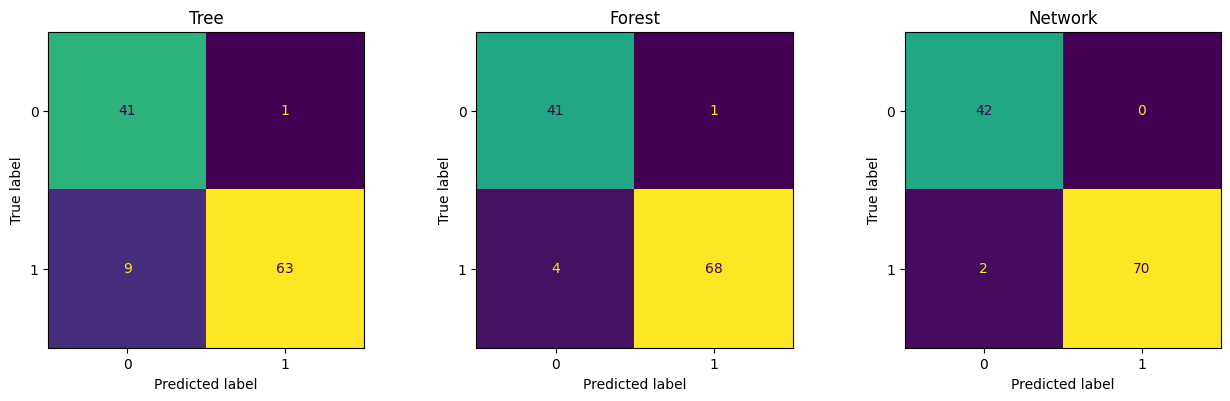

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y[test], model.predict(X[test]), ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Practice

Explain which observations teach the models, which observations can guide a setting change, and which observations assess the frozen comparison. Describe one mistake visible in the predictions. State one limitation shared by all methods in this experiment.

<details><summary>Feedback after your attempt</summary>

Fitting data determine model parameters and preprocessing. Validation can guide settings. Test evaluates the fixed procedure. Every model shares the available input representation and the chosen data split. A flexible estimator can still miss information absent from its inputs or fail on a different population. Predictions and errors need to be inspected alongside a single score.

</details>

In [9]:
with open("results/simple_breast_cancer_tree.json", "w") as stream:
    json.dump({"task": "Classifying cell-nucleus measurements", "metric": "balanced accuracy",
               "split_sizes": [len(fit), len(val), len(test)],
               "validation": validation_rows, "test": test_rows}, stream, indent=2)